In [ ]:
import torch
x = torch.randn(10, 10).cuda()
y = x @ x.T
print(f"GPU works: {y.sum().item():.4f}")

GPU works: 204.9660


In [ ]:
import torch
x = torch.randn(10, 10).cuda()
print(f"GPU works: {(x @ x.T).sum().item():.4f}")

GPU works: 244.7698


In [ ]:
import os
print(f"Drive mounted: {os.path.exists('/content/drive/Shareddrives')}")
print(f"WAV files ready: {os.path.exists('/content/MOSEI_wav_flat')}")
print(f"MP4 files ready: {os.path.exists('/content/MOSEI_faces_flat')}")

Drive mounted: False
WAV files ready: False
MP4 files ready: False


In [ ]:
# Mount & Install
from google.colab import drive
drive.mount('/content/drive')

!unzip -Z -1 "/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/Raw_Wav.zip" | grep -v "__MACOSX" | grep -v "^\._" | grep "\.wav$" | wc -l
!unzip -q "/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/Raw_Wav.zip" -d /content/MOSEI_wav
!find /content/MOSEI_wav -name "._*" -delete
!rm -rf /content/MOSEI_wav/__MACOSX
!find /content/MOSEI_wav -name "*.wav" | wc -l

import os
WAV_DIR = "/content/MOSEI_wav"
print("Top level:")
top = os.listdir(WAV_DIR)
print(top[:5])
first = os.path.join(WAV_DIR, top[0])
if os.path.isdir(first):
    print(f"\nInside {top[0]}:")
    print(os.listdir(first)[:5])

import os, shutil
SRC_DIR  = "/content/MOSEI_wav/Raw_Wav"
FLAT_DIR = "/content/MOSEI_wav_flat"
OUTPUT_DIR       = "/content/drive/Shareddrives/AI Capstone/Middle Fusion/fusion-mosei-best"
os.makedirs(FLAT_DIR, exist_ok=True)
count = 0
for video_id in os.listdir(SRC_DIR):
    video_path = os.path.join(SRC_DIR, video_id)
    if not os.path.isdir(video_path):
        continue
    for fname in os.listdir(video_path):
        if not fname.endswith(".wav"):
            continue
        clip_id = fname.replace(".wav", "")
        src = os.path.join(video_path, fname)
        dst = os.path.join(FLAT_DIR, f"{video_id}__{clip_id}.wav")
        shutil.copy2(src, dst)
        count += 1
print(f"Done: {count} wav files flattened to {FLAT_DIR}")

!unzip -q "/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/Raw-Cropped-FULL.zip" -d /content/MOSEI_faces
!find /content/MOSEI_faces -name "._*" -delete
!rm -rf /content/MOSEI_faces/__MACOSX

SRC_DIR = "/content/MOSEI_faces/Raw-Cropped-FULL"
FLAT_DIR = "/content/MOSEI_faces_flat"
os.makedirs(FLAT_DIR, exist_ok=True)
count = 0
for video_id in os.listdir(SRC_DIR):
    video_path = os.path.join(SRC_DIR, video_id)
    if not os.path.isdir(video_path):
        continue
    for fname in os.listdir(video_path):
        if not fname.endswith(".mp4"):
            continue
        src = os.path.join(video_path, fname)
        dst = os.path.join(FLAT_DIR, f"{video_id}__{fname}")
        shutil.copy2(src, dst)
        count += 1
print(f"Done: {count} files flattened to {FLAT_DIR}")

CSV_SRC = "/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/label_FULLY_PRUNED.csv"
CSV_DST = "/content/label_FULLY_PRUNED.csv"
shutil.copy2(CSV_SRC, CSV_DST)
print(f"CSV copied to {CSV_DST}")

Mounted at /content/drive
22856
22856
Top level:
['Raw_Wav']

Inside Raw_Wav:
['2o2ljA0QD7g', '244817', '4YfyP0uIqw0', 'CU6U-gS76K4', '4oeKDFIaL7o']
Done: 22856 wav files flattened to /content/MOSEI_wav_flat
Done: 22856 files flattened to /content/MOSEI_faces_flat
CSV copied to /content/label_FULLY_PRUNED.csv


In [ ]:
!pip install -q einops decord
!pip install -q timm==0.4.12
!git clone https://github.com/sunlicai/MAE-DFER.git /content/MAE-DFER

import sys
sys.path.insert(0, '/content/MAE-DFER')
import modeling_finetune
from timm.models import create_model

import os, gc, random, shutil, copy, contextlib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import soundfile as sf
import cv2
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import (
    HubertModel,
    AutoModel,
    AutoTokenizer,
    AutoFeatureExtractor,
    get_cosine_schedule_with_warmup,
)
from sklearn.metrics import mean_absolute_error
from scipy.stats import pearsonr
import collections

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 113.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 377.0/377.0 kB 10.3 MB/s eta 0:00:00
Cloning into '/content/MAE-DFER'...
remote: Enumerating objects: 259, done.
remote: Counting objects: 100% (78/78), done.
remote: Compressing objects: 100% (61/61), done.
remote: Total 259 (delta 50), reused 17 (delta 17), pack-reused 181 (from 1)
Receiving objects: 100% (259/259), 16.52 MiB | 37.42 MiB/s, done.
Resolving deltas: 100% (98/98), done.


In [ ]:
# Paths
ENRICHED_CSV     = "/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/label_FULLY_PRUNED.csv"
PREPROCESSED_CSV = "/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/label_text_FULLY_PRUNED.csv"
FLAT_WAV_DIR     = "/content/MOSEI_wav_flat"
FLAT_MP4_DIR     = "/content/MOSEI_faces_flat"
OUTPUT_DIR       = "/content/drive/Shareddrives/AI Capstone/Middle Fusion/fusion-mosei-v61-clean"
os.makedirs(OUTPUT_DIR, exist_ok=True)

HUBERT_WEIGHTS   = "/content/drive/Shareddrives/AI Capstone/Audio Models/hubert-mosei-multitask-llrd/best_model.pt"
DEBERTA_WEIGHTS  = "/content/drive/Shareddrives/AI Capstone/Text model/deberta_model/best_model_v2.pt"
MAEDFER_WEIGHTS  = "/content/drive/Shareddrives/AI Capstone/Video Models/MAE-DFER/Checkpoints (Final Model)/best_model.pt"
MAEDFER_PRETRAIN = "/content/drive/Shareddrives/AI Capstone/Video Models/MAE-DFER/Pretrained/checkpoint-49.pth"

RESUME_CKPT      = f"{OUTPUT_DIR}/resume_checkpoint_v61b.pt"

HUBERT_CHECKPOINT  = "facebook/hubert-base-ls960"
DEBERTA_CHECKPOINT = "microsoft/deberta-v3-base"

HUBERT_DIM  = 768
DEBERTA_DIM = 768
MAEDFER_DIM = 512

NUM_FRAMES    = 16
IMAGE_SIZE    = 160
VIDEO_MEAN    = [0.5, 0.5, 0.5]
VIDEO_STD     = [0.5, 0.5, 0.5]
SAMPLE_RATE   = 16_000
MAX_AUDIO_LEN = int(8.0 * SAMPLE_RATE)
MAX_TEXT_LEN  = 128

BATCH_SIZE       = 16
GRAD_ACCUM       = 2
MAX_EPOCHS       = 200
PATIENCE         = 15
LR_FUSION        = 5e-5      # v6.1b: 5e-5
WD               = 0.01
WARMUP_RATIO     = 0.05
SEED             = 42
D_MODEL          = 256
NUM_HEADS        = 8
DROPOUT_PROB     = 0.35
CCC_ALPHA        = 0.6
LABEL_SMOOTHING  = 0.05
SENTIMENT_WEIGHT = 1.0
EMOTION_WEIGHT   = 1.0
POOL_LEN         = 16

# Sample-conditional gate init logits [text, audio, video, fuse]
MIXTURE_INIT_SENT = [ 0.0, -1.3, -2.4, -0.8]
MIXTURE_INIT_EMOT = [-1.3,  0.0, -2.4, -0.8]

EMOTION_COLS      = ["happy", "sad", "anger", "fear", "disgust", "surprise"]
EMOTION_THRESHOLD = 0.5
V6_BEST_AVG_CCC   = 0.4307   # carry over from prior best

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

# Metrics & losses
def ccc_np(y_true, y_pred):
    y_true = np.array(y_true, dtype=np.float64)
    y_pred = np.array(y_pred, dtype=np.float64)
    if np.std(y_true) < 1e-8 or np.std(y_pred) < 1e-8:
        return 0.0, 0.0
    rho, _ = pearsonr(y_true, y_pred)
    num = 2.0 * rho * np.std(y_true) * np.std(y_pred)
    den = np.var(y_true) + np.var(y_pred) + (np.mean(y_true) - np.mean(y_pred))**2
    return float(num / den if den > 1e-8 else 0.0), float(rho)


def ccc_loss_single(pred, target):
    mp, mt = pred.mean(), target.mean()
    cov    = ((pred - mp) * (target - mt)).mean()
    sp, st = pred.std(), target.std()
    if st < 1e-3 or sp < 1e-3:
        return torch.tensor(0.0, device=pred.device, requires_grad=True)
    denom = sp**2 + st**2 + (mp - mt)**2 + 1e-4
    return 1.0 - (2.0 * cov) / denom


def sentiment_loss(pred, target, alpha=CCC_ALPHA):
    return alpha * ccc_loss_single(pred, target) + (1.0 - alpha) * F.mse_loss(pred, target)


def emotion_loss(pred, target, emotion_weights, alpha=CCC_ALPHA, smoothing=LABEL_SMOOTHING):
    target_smooth = target * (1.0 - smoothing) + 0.5 * smoothing
    ccc = torch.stack([
        ccc_loss_single(pred[:, i], target[:, i]) * emotion_weights[i]
        for i in range(pred.shape[1])
    ]).mean()
    w   = emotion_weights.unsqueeze(0).expand_as(pred)
    bce = F.binary_cross_entropy(pred.clamp(1e-6, 1 - 1e-6), target_smooth.clamp(0, 1), weight=w)
    return alpha * ccc + (1.0 - alpha) * bce


def sentiment_to_class(score):
    if score > 0:   return "Positive"
    elif score < 0: return "Negative"
    else:           return "Neutral"


def emotion_vector_to_labels(pred_vector, threshold=EMOTION_THRESHOLD):
    dominant = EMOTION_COLS[int(np.argmax(pred_vector))]
    present  = [EMOTION_COLS[i] for i, v in enumerate(pred_vector) if v >= threshold]
    return dominant, present

Device: cuda
GPU  : NVIDIA A100-SXM4-40GB
VRAM : 42.4 GB


In [ ]:
HUBERT_CHECKPOINT  = "facebook/hubert-base-ls960"
DEBERTA_CHECKPOINT = "microsoft/deberta-v3-base"

HUBERT_DIM  = 768
DEBERTA_DIM = 768
MAEDFER_DIM = 512

NUM_FRAMES  = 16
IMAGE_SIZE  = 160
VIDEO_MEAN  = [0.5, 0.5, 0.5]
VIDEO_STD   = [0.5, 0.5, 0.5]

SAMPLE_RATE   = 16_000
MAX_AUDIO_LEN = int(8.0 * SAMPLE_RATE)
MAX_TEXT_LEN  = 128

BATCH_SIZE       = 16
GRAD_ACCUM       = 2
MAX_EPOCHS       = 200       # fine-tuning phase budget
PATIENCE         = 15        # more generous — plateau scheduler handles LR first
LR_FUSION        = 3e-5
WARMUP_RATIO     = 0.05      # shorter warmup — already initialised from v1
SEED             = 42
D_MODEL          = 256
NUM_HEADS        = 8
DROPOUT_PROB     = 0.35      # slightly higher than v1 (0.3) to combat overfitting
CCC_ALPHA        = 0.6
LABEL_SMOOTHING  = 0.05
EMA_DECAY        = 0.999
SENTIMENT_WEIGHT = 1.0
EMOTION_WEIGHT   = 1.0

EMOTION_COLS      = ["happy", "sad", "anger", "fear", "disgust", "surprise"]
EMOTION_THRESHOLD = 0.5

# Carry over best avg CCC from v1 so we only save if we actually improve
#V1_BEST_AVG_CCC = 0.4018

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if device.type == "cuda":
    print(f"GPU  : {torch.cuda.get_device_name(0)}")
    print(f"VRAM : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


# Metrics
def ccc_np(y_true, y_pred):
    y_true = np.array(y_true, dtype=np.float64)
    y_pred = np.array(y_pred, dtype=np.float64)
    if np.std(y_true) < 1e-8 or np.std(y_pred) < 1e-8:
        return 0.0, 0.0
    rho, _    = pearsonr(y_true, y_pred)
    std_true  = np.std(y_true)
    std_pred  = np.std(y_pred)
    mean_true = np.mean(y_true)
    mean_pred = np.mean(y_pred)
    num       = 2.0 * rho * std_true * std_pred
    den       = std_true**2 + std_pred**2 + (mean_true - mean_pred)**2
    return float(num / den if den > 1e-8 else 0.0), float(rho)


# Loss functions
def ccc_loss_single(pred, target):
    mean_p = pred.mean()
    mean_t = target.mean()
    cov    = ((pred - mean_p) * (target - mean_t)).mean()
    std_p  = pred.std()
    std_t  = target.std()
    # If either side is degenerate this batch, skip the CCC term —
    # backward through cov/denom blows up when denom ~ 1e-8
    if std_t < 1e-3 or std_p < 1e-3:
        return torch.tensor(0.0, device=pred.device, requires_grad=True)
    denom = std_p**2 + std_t**2 + (mean_p - mean_t)**2 + 1e-4
    return 1.0 - (2.0 * cov) / denom


def sentiment_loss(pred, target, alpha=CCC_ALPHA):
    ccc = ccc_loss_single(pred, target)
    mse = F.mse_loss(pred, target)
    return alpha * ccc + (1.0 - alpha) * mse


def emotion_loss(pred, target, emotion_weights, alpha=CCC_ALPHA, smoothing=LABEL_SMOOTHING):
    target_smooth = target * (1.0 - smoothing) + 0.5 * smoothing

    # Weighted per-channel CCC
    ccc = torch.stack([
        ccc_loss_single(pred[:, i], target[:, i]) * emotion_weights[i]
        for i in range(pred.shape[1])
    ]).mean()

    # Weighted BCE — weight tensor broadcast across batch
    w = emotion_weights.unsqueeze(0).expand_as(pred)  # (B, 6)
    bce = F.binary_cross_entropy(pred.clamp(1e-7, 1.0 - 1e-7), target_smooth.clamp(0, 1), weight=w)

    return alpha * ccc + (1.0 - alpha) * bce


# Label helpers
def sentiment_to_class(score):
    if score > 0:   return "Positive"
    elif score < 0: return "Negative"
    else:           return "Neutral"


def emotion_vector_to_labels(pred_vector, threshold=EMOTION_THRESHOLD):
    dominant = EMOTION_COLS[int(np.argmax(pred_vector))]
    present  = [EMOTION_COLS[i] for i, v in enumerate(pred_vector) if v >= threshold]
    return dominant, present


Device: cuda
GPU  : NVIDIA A100-SXM4-40GB
VRAM : 42.4 GB


In [ ]:
# Load labels + corrected text preprocessing merge
df = pd.read_csv(ENRICHED_CSV)
df["video_id"] = df["video_id"].astype(str)
df["clip_id"]  = df["clip_id"].astype(str)
df["wav_path"] = df.apply(lambda r: f"{FLAT_WAV_DIR}/{r['video_id']}__{r['clip_id']}.wav", axis=1)
df["mp4_path"] = df.apply(lambda r: f"{FLAT_MP4_DIR}/{r['video_id']}__{r['clip_id']}.mp4", axis=1)

before = len(df)
df = df[df["wav_path"].apply(os.path.exists) & df["mp4_path"].apply(os.path.exists)].copy()
print(f"Loaded {before} rows → kept {len(df)} with matching files")

df["sentiment_norm"] = df["sentiment"].clip(-3, 3) / 3.0
for col in EMOTION_COLS:
    df[col] = df[col].clip(0, 1)

# Corrected merge: match on label-tuple + within-key position
# Row-position joins break when CSVs drop different subsets. Label-tuple
# keys are stable across filtering pipelines.
df_uni = pd.read_csv(PREPROCESSED_CSV)
df_uni = df_uni.dropna(subset=['text'])
df_uni['text'] = df_uni['text'].astype(str).str.strip()
df_uni = df_uni[df_uni['text'] != ''].reset_index(drop=True)

key_cols = ['mode', 'sentiment', 'happy', 'sad', 'anger', 'fear', 'disgust', 'surprise']

df = df.reset_index(drop=True)
df['_pos_in_key']     = df.groupby(key_cols).cumcount()
df_uni['_pos_in_key'] = df_uni.groupby(key_cols).cumcount()

df_uni_subset = df_uni[key_cols + ['_pos_in_key', 'text']].rename(columns={'text': 'text_preprocessed'})
df = df.merge(df_uni_subset, on=key_cols + ['_pos_in_key'], how='left').drop(columns=['_pos_in_key'])
df = df[df['text_preprocessed'].notna()].reset_index(drop=True)

train_df = df[df["mode"] == "train"].reset_index(drop=True)
val_df   = df[df["mode"] == "valid"].reset_index(drop=True)
test_df  = df[df["mode"] == "test"].reset_index(drop=True)
print(f"Train: {len(train_df)}  Val: {len(val_df)}  Test: {len(test_df)}")
print("Using official MOSEI split — consistent with unimodal baselines")

Loaded 19970 rows
Dropped 0 missing files  |  Remaining: 19970
Train: 14179  |  Val: 1671  |  Test: 4120
Using official MOSEI split — consistent with unimodal baselines


In [ ]:
# Compute from actual training distribution so weights reflect real imbalance.
# Floor of 0.05 prevents division explosion for very rare emotions.
# Clip at 5.0 prevents any single emotion from dominating gradients.
# Normalise to mean=1 so total loss magnitude stays comparable to v1.
print("\nEmotion label distribution (train):")
emotion_means = train_df[EMOTION_COLS].mean().values
for col, m in zip(EMOTION_COLS, emotion_means):
    print(f"  {col:<10}: mean={m:.4f}")

raw_weights    = 1.0 / (emotion_means + 0.05)
raw_weights    = np.clip(raw_weights, None, 5.0)
raw_weights    = raw_weights / raw_weights.mean()   # normalise to mean=1
EMOTION_WEIGHTS = torch.tensor(raw_weights, dtype=torch.float32).to(device)

print("\nEmotion loss weights (inverse-frequency, clipped, normalised):")
for col, w in zip(EMOTION_COLS, raw_weights):
    print(f"  {col:<10}: {w:.3f}")


Emotion label distribution (train):
  happy     : mean=0.3713
  sad       : mean=0.1486
  anger     : mean=0.1354
  fear      : mean=0.0465
  disgust   : mean=0.1067
  surprise  : mean=0.0406

Emotion loss weights (inverse-frequency, clipped, normalised):
  happy     : 0.520
  sad       : 1.096
  anger     : 1.096
  fear      : 1.096
  disgust   : 1.096
  surprise  : 1.096


In [ ]:
# Dataset
audio_feature_extractor = AutoFeatureExtractor.from_pretrained(HUBERT_CHECKPOINT)
text_tokenizer          = AutoTokenizer.from_pretrained(DEBERTA_CHECKPOINT)

video_mean = np.array(VIDEO_MEAN, dtype=np.float32)
video_std  = np.array(VIDEO_STD,  dtype=np.float32)


def load_video_frames(mp4_path, num_frames=NUM_FRAMES, image_size=IMAGE_SIZE):
    cap   = cv2.VideoCapture(mp4_path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total < 1:
        cap.release()
        return torch.zeros(3, num_frames, image_size, image_size)
    indices = np.linspace(0, total - 1, num_frames, dtype=int)
    frames  = []
    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ok, frame = cap.read()
        if ok:
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frame = cv2.resize(frame, (image_size, image_size))
        else:
            frame = np.zeros((image_size, image_size, 3), dtype=np.uint8)
        frame = frame.astype(np.float32) / 255.0
        frame = (frame - video_mean) / video_std
        frames.append(frame)
    cap.release()
    video = np.stack(frames, axis=0)
    video = torch.from_numpy(video).permute(3, 0, 1, 2)
    return video


class MOSEIFusionDataset(Dataset):
    def __init__(self, df):
        self.df = df

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        try:
            audio, _ = sf.read(row["wav_path"], dtype="float32")
        except Exception:
            audio = np.zeros(MAX_AUDIO_LEN, dtype=np.float32)
        if len(audio) > MAX_AUDIO_LEN:
            audio = audio[:MAX_AUDIO_LEN]
        text  = str(row["text"]) if pd.notna(row.get("text", "")) else ""
        video = load_video_frames(row["mp4_path"])
        sentiment = float(row["sentiment_norm"])
        emotions  = [float(row[c]) for c in EMOTION_COLS]
        return audio, text, video, sentiment, emotions


def collate_fn(batch):
    audios, texts, videos, sentiments, emotions = zip(*batch)
    audio_inputs = audio_feature_extractor(
        list(audios), sampling_rate=SAMPLE_RATE,
        max_length=MAX_AUDIO_LEN, truncation=True,
        padding="max_length", return_tensors="pt",
    )
    text_inputs = text_tokenizer(
        list(texts), padding=True, truncation=True,
        max_length=MAX_TEXT_LEN, return_tensors="pt",
    )
    video_tensor = torch.stack(list(videos))
    return {
        "input_values":     audio_inputs["input_values"],
        "input_ids":        text_inputs["input_ids"],
        "attention_mask":   text_inputs["attention_mask"],
        "pixel_values":     video_tensor,
        "sentiment_labels": torch.tensor(sentiments, dtype=torch.float32),
        "emotion_labels":   torch.tensor(emotions,   dtype=torch.float32),
    }


train_loader = DataLoader(MOSEIFusionDataset(train_df), batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=8, collate_fn=collate_fn,
                          pin_memory=True)
val_loader   = DataLoader(MOSEIFusionDataset(val_df),   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=8, collate_fn=collate_fn,
                          pin_memory=True)
test_loader  = DataLoader(MOSEIFusionDataset(test_df),  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=8, collate_fn=collate_fn,
                          pin_memory=True)
print(f"Batches — train: {len(train_loader)}  val: {len(val_loader)}  test: {len(test_loader)}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/213 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

Batches — train: 887  val: 105  test: 258


In [ ]:
# Load backbones with partial unfreezing
def freeze_all(model):
    for param in model.parameters():
        param.requires_grad = False
    return model

def unfreeze_last_n_layers(model, n, layer_attr_path):
    obj = model
    for attr in layer_attr_path:
        obj = getattr(obj, attr)
    total = len(obj)
    for i, layer in enumerate(obj):
        if i >= total - n:
            for p in layer.parameters():
                p.requires_grad = True
    return total

print("Loading HuBERT…")
hubert = HubertModel.from_pretrained(HUBERT_CHECKPOINT)
state  = torch.load(HUBERT_WEIGHTS, map_location=device, weights_only=False)
if "model_state_dict" in state:
    state = state["model_state_dict"]
hubert_state = {k: v for k, v in state.items() if k.startswith("hubert.")}
hubert_state = {k[len("hubert."):]: v for k, v in hubert_state.items()}

if hubert_state:
    missing, unexpected = hubert.load_state_dict(hubert_state, strict=False)
    print("HuBERT load report:")
    print(f"  Missing keys: {len(missing)}")
    if missing:
        print(f"  First few missing: {missing[:5]}")
    print(f"  Unexpected keys: {len(unexpected)}")
    if unexpected:
        print(f"  First few unexpected: {unexpected[:5]}")
else:
    print("  Warning: no hubert.* keys found — using pretrained weights only")

hubert = freeze_all(hubert)
total_hubert_layers = unfreeze_last_n_layers(hubert, 2, ("encoder", "layers"))
hubert = hubert.to(device)
hubert.eval()

hubert.feature_extractor._requires_grad = False
for p in hubert.feature_extractor.parameters():
    p.requires_grad = False
hubert.config.apply_spec_augment = False

n_trainable_hubert = sum(p.numel() for p in hubert.parameters() if p.requires_grad)
print(f"  Unfroze last 2 of {total_hubert_layers} layers → {n_trainable_hubert:,} trainable params")

print("Loading DeBERTa…")
deberta = AutoModel.from_pretrained(DEBERTA_CHECKPOINT)
state   = torch.load(DEBERTA_WEIGHTS, map_location=device, weights_only=False)
if "model_state_dict" in state:
    state = state["model_state_dict"]

# Filter to keys with the 'encoder.' prefix (your wrapper class wrapped
# the DeBERTa model under self.encoder) and strip it. The remaining keys
# like 'encoder.layer.0...' map directly to the HF DeBERTa state dict.
deberta_state = {k[len("encoder."):]: v
                 for k, v in state.items()
                 if k.startswith("encoder.")}

missing, unexpected = deberta.load_state_dict(deberta_state, strict=False)
print("DeBERTa load report:")
print(f"  Filtered to {len(deberta_state)} keys from {len(state)} total")
print(f"  Missing keys: {len(missing)}")
if missing:
    print(f"  First few missing: {missing[:5]}")
print(f"  Unexpected keys: {len(unexpected)}")
if unexpected:
    print(f"  First few unexpected: {unexpected[:5]}")

deberta = freeze_all(deberta)
total_deberta_layers = unfreeze_last_n_layers(deberta, 2, ("encoder", "layer"))
deberta = deberta.to(device)
deberta.eval()

n_trainable_deberta = sum(p.numel() for p in deberta.parameters() if p.requires_grad)
print(f"  Unfroze last 2 of {total_deberta_layers} layers → {n_trainable_deberta:,} trainable params")

print("Loading MAE-DFER… (staying fully frozen)")

class MAEDFERBackbone(nn.Module):
    def __init__(self, pretrain_ckpt):
        super().__init__()
        self.backbone = create_model(
            'vit_base_dim512_no_depth_patch16_160',
            pretrained=False,
            num_classes=7,
            all_frames=NUM_FRAMES,
            tubelet_size=2,
            use_mean_pooling=True,
            attn_type='local_global',
            lg_region_size=(2, 5, 10),
            lg_first_attn_type='self',
            lg_third_attn_type='cross',
            lg_attn_param_sharing_first_third=False,
            lg_attn_param_sharing_all=False,
            lg_classify_token_type='org',
            lg_no_second=False,
            lg_no_third=False,
            drop_path_rate=0.1,
            init_values=0.0,
        )
        self.backbone.head = nn.Identity()
        ckpt       = torch.load(pretrain_ckpt, map_location='cpu', weights_only=False)
        state_dict = ckpt['model'] if 'model' in ckpt else ckpt
        self.backbone.load_state_dict(state_dict, strict=False)

    def forward(self, x):
        return self.backbone(x)

maedfer  = MAEDFERBackbone(MAEDFER_PRETRAIN)
ft_state = torch.load(MAEDFER_WEIGHTS, map_location=device, weights_only=False)
if "model_state_dict" in ft_state:
    ft_state = ft_state["model_state_dict"]
backbone_state = {
    k.replace("backbone.", ""): v
    for k, v in ft_state.items()
    if not k.startswith("head.")
}
maedfer.backbone.load_state_dict(backbone_state, strict=False)
maedfer = freeze_all(maedfer).eval().to(device)
print("  MAE-DFER fully frozen")

print("\nBackbone summary:")
print(f"  HuBERT  : {n_trainable_hubert:>10,} trainable")
print(f"  DeBERTa : {n_trainable_deberta:>10,} trainable")
print(f"  MAE-DFER: {'0':>10}   (frozen)")

if device.type == "cuda":
    allocated = torch.cuda.memory_allocated(device) / 1e9
    print(f"\nVRAM after loading backbones: {allocated:.2f} GB")

Loading HuBERT…


Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

HuBERT load report:
  Missing keys: 0
  Unexpected keys: 0
  Unfroze last 2 of 12 layers → 14,175,744 trainable params
Loading DeBERTa…


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.dense.weight           | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DeBERTa load report:
  Filtered to 198 keys from 214 total
  Missing keys: 0
  Unexpected keys: 0
  Unfroze last 2 of 12 layers → 14,175,744 trainable params
Loading MAE-DFER… (staying fully frozen)
==> Note: Use 'local_global' for compute reduction (lg_region_size=(2, 5, 10),lg_first_attn_type=self, lg_third_attn_type=cross,lg_attn_param_sharing_first_third=False,lg_attn_param_sharing_all=False,lg_classify_token_type=org,lg_no_second=False, lg_no_third=False)
==> Number of local regions: 8 (size=[4, 2, 1])
  MAE-DFER fully frozen

Backbone summary:
  HuBERT  : 14,175,744 trainable
  DeBERTa : 14,175,744 trainable
  MAE-DFER:          0   (frozen)

VRAM after loading backbones: 4.00 GB


In [ ]:
bad_mem = [name for name, p in deberta.named_parameters()
           if not torch.isfinite(p).all()]
print(f"Non-finite DeBERTa params after reload: {len(bad_mem)}")

Non-finite DeBERTa params after reload: 0


In [ ]:
# Clean cross-attention middle fusion
# Design principles (everything else cut):
#   1. Pool sequences to fixed short length BEFORE cross-attention so
#      modalities operate at comparable granularity (16 tokens each).
#   2. Two completely independent fusion paths — one per task.
#   3. Per-task learnable [CLS] query attends to all three modalities.
#   4. Modality dropout from epoch 1, applied to the pooled sequences.
#   5. Single cross-attention layer per task. No stacking.
#   6. No EMA, no LayerScale, no aux losses, no routers, no gates.

POOL_LEN = 16   # pooled sequence length per modality

class SequencePool(nn.Module):
    def __init__(self, d_model, pool_len=POOL_LEN):
        super().__init__()
        self.queries = nn.Parameter(torch.randn(pool_len, d_model) * 0.02)
        self.attn    = nn.MultiheadAttention(d_model, num_heads=4,
                                              dropout=0.1, batch_first=True)
        self.norm    = nn.LayerNorm(d_model)

    def forward(self, x):
        B    = x.size(0)
        q    = self.queries.unsqueeze(0).expand(B, -1, -1)
        out, _ = self.attn(q, x, x)
        return self.norm(out)


class TaskFusionPath(nn.Module):
    def __init__(self, d_model, num_heads, out_dim, dropout=0.2):
        super().__init__()
        self.cls_query = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)
        self.cross_attn = nn.MultiheadAttention(d_model, num_heads,
                                                 dropout=0.1, batch_first=True)
        self.norm1 = nn.LayerNorm(d_model)
        # Small FFN refinement of the CLS output
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_model * 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model * 2, d_model),
        )
        self.norm2 = nn.LayerNorm(d_model)
        # Prediction head
        self.head = nn.Sequential(
            nn.Linear(d_model, d_model // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model // 2, out_dim),
        )

    def forward(self, t_pool, a_pool, v_pool):
        B = t_pool.size(0)
        # Concatenate modality sequences — model has no way to distinguish
        # which token came from which modality EXCEPT via the content itself,
        # which is exactly what cross-attention is for.
        kv  = torch.cat([t_pool, a_pool, v_pool], dim=1)   # (B, 3*POOL_LEN, d_model)
        cls = self.cls_query.expand(B, -1, -1)             # (B, 1, d_model)
        attended, _ = self.cross_attn(cls, kv, kv)
        cls_out     = self.norm1(cls + attended)
        ffn_out     = self.ffn(cls_out)
        cls_out     = self.norm2(cls_out + ffn_out)
        return self.head(cls_out.squeeze(1))


class CrossAttentionFusionV4(nn.Module):
    def __init__(self, d_model=D_MODEL, num_heads=NUM_HEADS, dropout=DROPOUT_PROB):
        super().__init__()
        self.dropout_prob = 0.20

        self.text_proj  = nn.Linear(DEBERTA_DIM, d_model)
        self.audio_proj = nn.Linear(HUBERT_DIM,  d_model)
        self.video_proj = nn.Linear(MAEDFER_DIM, d_model)

        # Text and audio: variable-length sequences → POOL_LEN
        # Video: single vector → expand to POOL_LEN via broadcast (no pool)
        self.text_pool  = SequencePool(d_model, POOL_LEN)
        self.audio_pool = SequencePool(d_model, POOL_LEN)
        # Video has no sequence to pool — just LayerNorm + repeat
        self.video_norm = nn.LayerNorm(d_model)

        # Each path has its own CLS query, cross-attention, FFN, and head.
        # No parameter sharing between sentiment and emotion fusion.
        self.sent_path = TaskFusionPath(d_model, num_heads, out_dim=1, dropout=dropout)
        self.emot_path = TaskFusionPath(d_model, num_heads, out_dim=6, dropout=dropout)

    def _modality_dropout(self, t, a, v):
        if not self.training:
            return t, a, v
        dev = t.device
        m_t = (torch.rand(1) > self.dropout_prob).float().to(dev)
        m_a = (torch.rand(1) > self.dropout_prob).float().to(dev)
        m_v = (torch.rand(1) > self.dropout_prob).float().to(dev)
        # Always keep at least one
        if (m_t + m_a + m_v).item() == 0:
            idx = torch.randint(0, 3, (1,)).item()
            if   idx == 0: m_t = torch.ones(1).to(dev)
            elif idx == 1: m_a = torch.ones(1).to(dev)
            else:          m_v = torch.ones(1).to(dev)
        scale = 3.0 / (m_t + m_a + m_v)
        # Broadcast mask over (B, L, d_model)
        return (t * m_t * scale, a * m_a * scale, v * m_v * scale)

    def forward(self, text_feat, video_feat, audio_feat,
                sentiment_labels=None, emotion_labels=None,
                emotion_weights=None):

        # Step 1 — Project to shared d_model
        t = self.text_proj(text_feat)                  # (B, L_text, d_model)
        a = self.audio_proj(audio_feat)                # (B, L_audio, d_model)
        v = self.video_proj(
            video_feat.unsqueeze(1) if video_feat.dim() == 2 else video_feat
        )                                              # (B, 1, d_model)

        # Step 2 — Pool to fixed length POOL_LEN
        # Text/audio: learnable-query attention pool
        # Video: LayerNorm then broadcast-repeat to POOL_LEN (no real pool needed)
        t_pool = self.text_pool(t)                     # (B, POOL_LEN, d_model)
        a_pool = self.audio_pool(a)                    # (B, POOL_LEN, d_model)
        v_pool = self.video_norm(v).expand(-1, POOL_LEN, -1)  # (B, POOL_LEN, d_model)

        # Step 3 — Modality dropout (training only) on pooled sequences
        t_pool, a_pool, v_pool = self._modality_dropout(t_pool, a_pool, v_pool)

        # Step 4 — Two independent task paths
        sent_logit = self.sent_path(t_pool, a_pool, v_pool).squeeze(-1)  # (B,)
        emot_logit = self.emot_path(t_pool, a_pool, v_pool)              # (B, 6)

        sent_pred = torch.tanh(sent_logit)
        emot_pred = torch.sigmoid(emot_logit)

        # Step 5 — Loss
        loss = None
        if sentiment_labels is not None and emotion_labels is not None:
            ew = emotion_weights if emotion_weights is not None \
                 else torch.ones(6, device=emot_pred.device)
            s_loss = sentiment_loss(sent_pred, sentiment_labels)
            e_loss = emotion_loss(emot_pred, emotion_labels, ew)
            loss = SENTIMENT_WEIGHT * s_loss + EMOTION_WEIGHT * e_loss

        return loss, sent_pred, emot_pred


fusion = CrossAttentionFusionV4().to(device)
print(f"v4 trainable params: {sum(p.numel() for p in fusion.parameters() if p.requires_grad):,}")

v4 trainable params: 2,182,535


In [ ]:
# Fusion-only optimizer
# Backbones are fully frozen for this run — DeBERTa fine-tuning hits a NaN
# in the AdamW kernel that we couldn't diagnose past, so we train fusion only.
# Backbone weights stay at their pretrained values (already strong on MOSEI).

RESUME_CKPT_V5 = f"{OUTPUT_DIR}/resume_checkpoint_v5.pt"

LR_FUSION_V5 = 5e-5
WD_V5        = 0.01

# Freeze all backbones explicitly — no gradient flow at all
for p in hubert.parameters():
    p.requires_grad = False
for p in deberta.parameters():
    p.requires_grad = False
# maedfer was already frozen in Cell 4

fusion_params = list(fusion.parameters())

optimizer = AdamW(
    [{"params": fusion_params, "lr": LR_FUSION_V5, "weight_decay": WD_V5}],
)

total_steps = (len(train_loader) // GRAD_ACCUM) * MAX_EPOCHS
scheduler   = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(total_steps * 0.05),
    num_training_steps=total_steps,
)

history = {
    "train_loss": [], "val_loss": [],
    "sent_ccc": [], "sent_plcc": [], "sent_mae": [],
    "mean_emot_ccc": [], "emot_mae": [],
}

best_avg_ccc   = 0.4018
best_epoch     = 0
patience_count = 0
start_epoch    = 1

if os.path.exists(RESUME_CKPT_V5):
    print(f"V5 resume checkpoint found — continuing…")
    ckpt = torch.load(RESUME_CKPT_V5, map_location=device, weights_only=False)
    fusion.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    scheduler.load_state_dict(ckpt["scheduler_state_dict"])
    best_avg_ccc   = ckpt["best_avg_ccc"]
    best_epoch     = ckpt["best_epoch"]
    patience_count = ckpt["patience_count"]
    history        = ckpt["history"]
    start_epoch    = ckpt["epoch"] + 1
    print(f"  Resumed from epoch {ckpt['epoch']}  |  best avg CCC: {best_avg_ccc:.4f}")
else:
    print("No v5 checkpoint — fresh start (fusion-only, backbones frozen)")

n_fusion_params = sum(p.numel() for p in fusion_params if p.requires_grad)
print(f"\nTrainable params: fusion={n_fusion_params:,}  backbone=0 (frozen)")
print(f"LR: fusion={LR_FUSION_V5}")
print(f"Start epoch: {start_epoch}  |  best avg CCC: {best_avg_ccc:.4f}")

No v5 checkpoint — fresh start (fusion-only, backbones frozen)

Trainable params: fusion=2,182,535  backbone=0 (frozen)
LR: fusion=5e-05
Start epoch: 1  |  best avg CCC: 0.4018


In [ ]:
def extract_features(batch, training=True):
    ctx = contextlib.nullcontext() if training else torch.no_grad()
    with ctx:
        input_values = batch["input_values"].to(device)
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        pixel_values = batch["pixel_values"].to(device)

        audio_feat = hubert(input_values=input_values).last_hidden_state.float()

        # Get all hidden states from DeBERTa to find where NaN first appears
        deberta_out = deberta(
            input_ids=input_ids,
            attention_mask=attention_mask,
            output_hidden_states=True
        )
        text_feat = deberta_out.last_hidden_state.float()

        # If NaN, show which layer first produced it
        if torch.isnan(text_feat).any():
            print(f"  DEBUG: hidden states NaN trace:")
            for i, h in enumerate(deberta_out.hidden_states):
                has_nan = torch.isnan(h).any().item()
                print(f"    Layer {i}: nan={has_nan}  range=[{h.min().item():.3f}, {h.max().item():.3f}]")

        with torch.no_grad():
            video_feat = maedfer(pixel_values)
    return text_feat, video_feat, audio_feat

In [ ]:
# Eval (no_grad, backbones in eval mode)
def evaluate(loader):
    fusion.eval()
    hubert.eval()
    deberta.eval()
    # maedfer stays in eval (always was)

    all_sent_pred, all_sent_true = [], []
    all_emot_pred, all_emot_true = [], []
    total_loss = 0.0

    with torch.no_grad():
        for batch in loader:
            text_feat, video_feat, audio_feat = extract_features(batch, training=False)
            slbl = batch["sentiment_labels"].to(device)
            elbl = batch["emotion_labels"].to(device)
            loss, sent_pred, emot_pred = fusion(
                text_feat, video_feat, audio_feat, slbl, elbl,
                emotion_weights=EMOTION_WEIGHTS,
            )
            total_loss += loss.item()
            all_sent_pred.extend((sent_pred.cpu().numpy() * 3).tolist())
            all_sent_true.extend((slbl.cpu().numpy()      * 3).tolist())
            all_emot_pred.extend(emot_pred.cpu().numpy().tolist())
            all_emot_true.extend(elbl.cpu().numpy().tolist())

    avg_loss        = total_loss / len(loader)
    sent_ccc_val, sent_plcc = ccc_np(all_sent_true, all_sent_pred)
    sent_mae                = mean_absolute_error(all_sent_true, all_sent_pred)
    all_emot_pred           = np.array(all_emot_pred)
    all_emot_true           = np.array(all_emot_true)
    emot_ccc_scores         = [ccc_np(all_emot_true[:, i], all_emot_pred[:, i])[0]
                                for i in range(len(EMOTION_COLS))]
    mean_emot_ccc           = float(np.mean(emot_ccc_scores))
    emot_mae                = mean_absolute_error(all_emot_true.flatten(), all_emot_pred.flatten())

    return (avg_loss, sent_ccc_val, sent_plcc, sent_mae,
            mean_emot_ccc, emot_ccc_scores, emot_mae,
            all_sent_pred, all_sent_true,
            all_emot_pred, all_emot_true)

In [ ]:
# Sanity check
gc.collect()
torch.cuda.empty_cache()
total = torch.cuda.get_device_properties(0).total_memory / 1e9
used  = torch.cuda.memory_allocated() / 1e9
print(f"Total VRAM : {total:.1f} GB  |  Used: {used:.2f} GB  |  Free: {total - used:.2f} GB")

print("\nTesting one batch…")
batch = next(iter(train_loader))
text_feat, video_feat, audio_feat = extract_features(batch)
loss, sp, ep = fusion(
    text_feat, video_feat, audio_feat,
    batch["sentiment_labels"].to(device),
    batch["emotion_labels"].to(device),
    emotion_weights=EMOTION_WEIGHTS,
)
assert loss.shape == torch.Size([]), f"Loss must be scalar, got {loss.shape}"
print(f"  loss={loss.item():.4f}  sent_pred={sp.shape}  emot_pred={ep.shape}")
(loss / GRAD_ACCUM).backward()
optimizer.zero_grad()
print(f"✓ One batch passed  |  VRAM: {torch.cuda.memory_allocated() / 1e9:.2f} GB")
gc.collect(); torch.cuda.empty_cache()

Total VRAM : 42.4 GB  |  Used: 3.38 GB  |  Free: 39.03 GB

Testing one batch…
  loss=1.3281  sent_pred=torch.Size([16])  emot_pred=torch.Size([16, 6])
✓ One batch passed  |  VRAM: 2.57 GB


In [ ]:
# Diagnostic — run BEFORE the training loop
import torch
gc.collect(); torch.cuda.empty_cache()

print("Forward-only diagnostic...")
fusion.train()
hubert.eval(); deberta.eval()

batch = next(iter(train_loader))
text_feat, video_feat, audio_feat = extract_features(batch, training=True)

print(f"text_feat   : min={text_feat.min().item():.3f}  max={text_feat.max().item():.3f}  has_nan={torch.isnan(text_feat).any().item()}")
print(f"audio_feat  : min={audio_feat.min().item():.3f}  max={audio_feat.max().item():.3f}  has_nan={torch.isnan(audio_feat).any().item()}")
print(f"video_feat  : min={video_feat.min().item():.3f}  max={video_feat.max().item():.3f}  has_nan={torch.isnan(video_feat).any().item()}")

loss, sp, ep = fusion(
    text_feat, video_feat, audio_feat,
    batch["sentiment_labels"].to(device),
    batch["emotion_labels"].to(device),
    emotion_weights=EMOTION_WEIGHTS,
)
print(f"loss        : {loss.item():.4f}  has_nan={torch.isnan(loss).item()}")
print(f"sent_pred   : min={sp.min().item():.4f}  max={sp.max().item():.4f}")
print(f"emot_pred   : min={ep.min().item():.4f}  max={ep.max().item():.4f}")

try:
    (loss / GRAD_ACCUM).backward()
    print("✓ Backward succeeded")
except RuntimeError as e:
    print(f"✗ Backward failed: {str(e)[:200]}")

optimizer.zero_grad()



Forward-only diagnostic...
text_feat   : min=-10.594  max=13.289  has_nan=False
audio_feat  : min=-9.073  max=7.901  has_nan=False
video_feat  : min=-3.204  max=3.577  has_nan=False
loss        : 1.3281  has_nan=False
sent_pred   : min=-0.3305  max=0.3821
emot_pred   : min=0.3065  max=0.6391
✓ Backward succeeded


In [ ]:
# Diagnostic — inspect DeBERTa checkpoint structure
import torch

state = torch.load(DEBERTA_WEIGHTS, map_location="cpu", weights_only=False)
if "model_state_dict" in state:
    state = state["model_state_dict"]

# Group keys by prefix
prefixes = {}
for k in state.keys():
    prefix = k.split(".")[0]
    prefixes[prefix] = prefixes.get(prefix, 0) + 1
print("Top-level prefixes in checkpoint:")
for p, c in sorted(prefixes.items()):
    print(f"  {p}: {c} keys")

# Show keys that contain 'deberta' or 'encoder'
sample = [k for k in state.keys() if "encoder" in k or "embedding" in k][:10]
print("\nSample relevant keys:")
for k in sample:
    print(f"  {k}")

Top-level prefixes in checkpoint:
  emotion_head: 4 keys
  encoder: 198 keys
  gru: 8 keys
  sentiment_head: 4 keys

Sample relevant keys:
  encoder.embeddings.word_embeddings.weight
  encoder.embeddings.LayerNorm.weight
  encoder.embeddings.LayerNorm.bias
  encoder.encoder.layer.0.attention.self.query_proj.weight
  encoder.encoder.layer.0.attention.self.query_proj.bias
  encoder.encoder.layer.0.attention.self.key_proj.weight
  encoder.encoder.layer.0.attention.self.key_proj.bias
  encoder.encoder.layer.0.attention.self.value_proj.weight
  encoder.encoder.layer.0.attention.self.value_proj.bias
  encoder.encoder.layer.0.attention.output.dense.weight


In [ ]:
import os, torch

print(f"Checkpoint exists on disk: {os.path.exists(RESUME_CKPT_V5)}")

# What's currently loaded in memory?
bad_mem = [name for name, p in deberta.named_parameters()
           if not torch.isfinite(p).all()]
print(f"Non-finite DeBERTa params in memory: {len(bad_mem)}")
if bad_mem:
    print("First few:", bad_mem[:5])

# Specifically check the unfrozen layers
for li in [10, 11]:
    layer = deberta.encoder.layer[li]
    any_bad = any(not torch.isfinite(p).all() for p in layer.parameters())
    print(f"  DeBERTa layer {li}: any non-finite = {any_bad}")

Checkpoint exists on disk: False
Non-finite DeBERTa params in memory: 0
  DeBERTa layer 10: any non-finite = False
  DeBERTa layer 11: any non-finite = False


In [ ]:
bad = [n for n, p in deberta.named_parameters() if not torch.isfinite(p).all()]
print(f"Non-finite DeBERTa params before training: {len(bad)}")

Non-finite DeBERTa params before training: 0


In [ ]:
bad_d = sum(1 for _, p in deberta.named_parameters() if not torch.isfinite(p).all())
bad_h = sum(1 for _, p in hubert.named_parameters() if not torch.isfinite(p).all())
bad_f = sum(1 for _, p in fusion.named_parameters() if not torch.isfinite(p).all())
print(f"Non-finite: deberta={bad_d}  hubert={bad_h}  fusion={bad_f}")  # all should be 0

Non-finite: deberta=0  hubert=0  fusion=0


In [ ]:
import os
if os.path.exists(RESUME_CKPT_V5):
    os.remove(RESUME_CKPT_V5)
    print(f"Deleted corrupted {RESUME_CKPT_V5}")

Deleted corrupted /content/drive/Shareddrives/AI Capstone/Middle Fusion/fusion-mosei-best/resume_checkpoint_v5.pt


In [ ]:
# Training loop with backbone training
# import collections   # add to your top-level imports

# # inside the (step + 1) % GRAD_ACCUM == 0 block, define this BEFORE the else branch:
# all_trainable = (
#     [p for p in fusion.parameters()  if p.requires_grad] +
#     backbone_params
# )

# Header
print(f"\n{'Ep':>3} {'TrLoss':>8} {'VlLoss':>8} "
      f"{'SCCC':>8} {'SPLCC':>8} {'SMAE':>8} {'ECCC':>8} {'P':>4}")
print("─" * 70)

best_fusion_state = copy.deepcopy(fusion.state_dict())

for epoch in range(start_epoch, MAX_EPOCHS + 1):
    fusion.train()

    tr_loss = 0.0
    optimizer.zero_grad()

    for step, batch in enumerate(train_loader):
        text_feat, video_feat, audio_feat = extract_features(batch, training=True)
        slbl = batch["sentiment_labels"].to(device)
        elbl = batch["emotion_labels"].to(device)

        # Sanity check inputs BEFORE forward
        if torch.isnan(text_feat).any() or torch.isinf(text_feat).any():
            print(f"  ✗ text_feat NaN/Inf at step {step}")
            optimizer.zero_grad(); continue
        if torch.isnan(audio_feat).any() or torch.isinf(audio_feat).any():
            print(f"  ✗ audio_feat NaN/Inf at step {step}")
            optimizer.zero_grad(); continue
        if torch.isnan(video_feat).any() or torch.isinf(video_feat).any():
            print(f"  ✗ video_feat NaN/Inf at step {step}")
            optimizer.zero_grad(); continue

        # Check labels
        if (elbl < 0).any().item() or (elbl > 1).any().item():
            print(f"  ✗ emotion label out of [0,1] at step {step}: min={elbl.min().item()}, max={elbl.max().item()}")
            optimizer.zero_grad(); continue
        if (slbl < -1).any().item() or (slbl > 1).any().item():
            print(f"  ✗ sentiment label out of [-1,1] at step {step}: min={slbl.min().item()}, max={slbl.max().item()}")
            optimizer.zero_grad(); continue

        # Single forward call
        loss, _, _ = fusion(
            text_feat, video_feat, audio_feat, slbl, elbl,
            emotion_weights=EMOTION_WEIGHTS,
        )

        # Check loss is finite — .item() forces CPU sync to avoid device assert
        if not torch.isfinite(loss).item():
            print(f"  ✗ Non-finite loss at step {step}, skipping")
            optimizer.zero_grad(); continue

        (loss / GRAD_ACCUM).backward()
        tr_loss += loss.item()

        if (step + 1) % GRAD_ACCUM == 0:
            # Guard: skip step if any gradient or optimizer state is non-finite
            bad_grad = False
            for p in fusion.parameters():
                if p.grad is not None and not torch.isfinite(p.grad).all():
                    bad_grad = True
                    break

            bad_state = False
            if not bad_grad:
                for group in optimizer.param_groups:
                    for p in group["params"]:
                        st = optimizer.state.get(p, {})
                        if "exp_avg" in st and not torch.isfinite(st["exp_avg"]).all():
                            bad_state = True; break
                        if "exp_avg_sq" in st and not torch.isfinite(st["exp_avg_sq"]).all():
                            bad_state = True; break
                    if bad_state:
                        break

            if bad_grad or bad_state:
                print(f"  ✗ step {step}: bad_grad={bad_grad}  bad_state={bad_state}")
                if bad_state:
                    optimizer.state = collections.defaultdict(dict)
                optimizer.zero_grad()
            else:
                torch.nn.utils.clip_grad_norm_(fusion.parameters(), 1.0)
                optimizer.step()
                scheduler.step()
                optimizer.zero_grad()

    tr_loss /= len(train_loader)

    (vl_loss,
     sent_ccc_val, sent_plcc, sent_mae,
     mean_emot_ccc, _, emot_mae,
     _, _, _, _) = evaluate(val_loader)

    avg_ccc = (sent_ccc_val + mean_emot_ccc) / 2.0

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(vl_loss)
    history["sent_ccc"].append(sent_ccc_val)
    history["sent_plcc"].append(sent_plcc)
    history["sent_mae"].append(sent_mae)
    history["mean_emot_ccc"].append(mean_emot_ccc)
    history["emot_mae"].append(emot_mae)

    improved = avg_ccc > best_avg_ccc
    if improved:
        best_avg_ccc, best_epoch, patience_count = avg_ccc, epoch, 0
    else:
        patience_count += 1

    flag = " ✓" if improved else ""
    print(f"{epoch:>3} {tr_loss:>8.4f} {vl_loss:>8.4f} "
          f"{sent_ccc_val:>8.4f} {sent_plcc:>8.4f} {sent_mae:>8.4f} {mean_emot_ccc:>8.4f} "
          f"{patience_count:>4}{flag}")

    # Save with backbone states — they're being updated now
    # Update in-memory best state when this epoch is the best
    if improved:
        best_fusion_state = copy.deepcopy(fusion.state_dict())

    ckpt_payload = {
        "epoch":                 epoch,
        "model_state_dict":      fusion.state_dict(),
        "best_model_state_dict": best_fusion_state,
        "optimizer_state_dict":  optimizer.state_dict(),
        "scheduler_state_dict":  scheduler.state_dict(),
        "best_avg_ccc":          best_avg_ccc,
        "best_epoch":            best_epoch,
        "patience_count":        patience_count,
        "history":               history,
    }
    def _all_finite(sd):
        return all(torch.isfinite(v).all().item()
                  for v in sd.values()
                  if torch.is_tensor(v) and v.is_floating_point())

    if _all_finite(fusion.state_dict()) and \
      _all_finite(hubert.state_dict()) and \
      _all_finite(deberta.state_dict()):
        torch.save(ckpt_payload, RESUME_CKPT_V5)
    else:
        print(f"  ⚠ Skipping ckpt save at epoch {epoch} — non-finite weights")

    if improved:
        print(f"  → New best! avg CCC={best_avg_ccc:.4f}  "
              f"(sent {sent_ccc_val:.4f}, emot {mean_emot_ccc:.4f})")

    if patience_count >= PATIENCE:
        print(f"\nEarly stop @ epoch {epoch}  |  best avg CCC {best_avg_ccc:.4f} @ epoch {best_epoch}")
        break

    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()


 Ep   TrLoss   VlLoss     SCCC    SPLCC     SMAE     ECCC    P
──────────────────────────────────────────────────────────────────────
  1   0.7517   1.0228   0.5222   0.5315   0.7001   0.2732    4
  2   0.7364   1.0287   0.5242   0.5297   0.7152   0.2724    5
  3   0.7219   1.0318   0.5079   0.5199   0.6975   0.2828    6
  4   0.7135   1.0217   0.5282   0.5340   0.7046   0.2845    0 ✓
  → New best! avg CCC=0.4064  (sent 0.5282, emot 0.2845)
  5   0.7081   1.0204   0.5145   0.5299   0.6900   0.2735    1
  6   0.7201   1.0147   0.5279   0.5350   0.7111   0.2824    2
  7   0.7103   1.0237   0.5302   0.5336   0.7219   0.2900    0 ✓
  → New best! avg CCC=0.4101  (sent 0.5302, emot 0.2900)
  8   0.7052   1.0231   0.5204   0.5336   0.6865   0.2803    1
  9   0.7068   1.0217   0.5301   0.5406   0.6894   0.2812    2
 10   0.7110   1.0200   0.5082   0.5371   0.6731   0.2811    3
 11   0.6948   1.0234   0.5255   0.5398   0.6785   0.2817    4
 12   0.6827   1.0250   0.5295   0.5385   0.7582   0.2

In [ ]:
# Test evaluation
print("Loading best model for test evaluation…")
ckpt = torch.load(RESUME_CKPT, map_location=device, weights_only=False)
fusion.load_state_dict(ckpt["best_model_state_dict"])
print(f"  Loaded epoch {ckpt['best_epoch']}  val avg CCC: {ckpt['best_avg_ccc']:.4f}")

test = evaluate(test_loader, return_per_modality=True)
sent_ccc  = test['sent_ccc']
emot_ccc  = test['mean_emot_ccc']
avg_ccc   = (sent_ccc + emot_ccc) / 2.0

print(f"\n── Combined predictions ────────────────────────────────────────")
print(f"  Sentiment CCC : {sent_ccc:.4f}    PLCC: {test['sent_plcc']:.4f}    MAE: {test['sent_mae']:.4f}")
print(f"  Emotion mean  : {emot_ccc:.4f}                              MAE: {test['emot_mae']:.4f}")
print(f"  Avg CCC       : {avg_ccc:.4f}")

print(f"\n── Per-emotion ─────────────────────────────────────────────────")
for i, col in enumerate(EMOTION_COLS):
    mae_i = mean_absolute_error(test['emot_true'][:, i], test['emot_pred'][:, i])
    print(f"  {col:<10}: CCC {test['emot_ccc_scores'][i]:>7.4f}   MAE {mae_i:.4f}")

print(f"\n── Mixture weights (test set average) ──────────────────────────")
print(f"  Sentiment [text, audio, video, fuse]: {test['w_sent'].round(3)}")
print(f"  Emotion   [text, audio, video, fuse]: {test['w_emot'].round(3)}")

print(f"\n── Per-modality source breakdown ───────────────────────────────")
print(f"  Sentiment CCC per source:")
for mod in ["text", "audio", "video", "fuse"]:
    c, _ = ccc_np(test["sent_true"], test["per_mod_sent"][mod])
    print(f"    {mod:<6}: {c:.4f}")
print(f"  Mean Emotion CCC per source:")
for mod in ["text", "audio", "video", "fuse"]:
    pred_arr = np.array(test["per_mod_emot"][mod])
    per_emo  = [ccc_np(test["emot_true"][:, i], pred_arr[:, i])[0] for i in range(6)]
    print(f"    {mod:<6}: {np.mean(per_emo):.4f}  ({', '.join(f'{c:.2f}' for c in per_emo)})")

print(f"\n── Comparison with unimodal baselines and prior fusion variants ─")
print(f"  HuBERT unimodal       : SCCC 0.5756   mECCC 0.3027   avg 0.4392  (best at emotion)")
print(f"  DeBERTa unimodal      : SCCC 0.6918   mECCC 0.1587   avg 0.4253  (best at sentiment)")
print(f"  MAE-DFER unimodal     : SCCC ~0.05    mECCC ~0.00    avg ~0.025  (degenerate)")
print(f"  v5  (middle fusion)   : SCCC 0.5302   mECCC 0.2900   avg 0.4101")
print(f"  v6  (late mixture)    : SCCC 0.5762   mECCC 0.2851   avg 0.4307")
print(f"  v6.1 (real heads)     : SCCC 0.6610   mECCC 0.2081   avg 0.4345")
print(f"  v6.1b (this, gated)   : SCCC {sent_ccc:.4f}   mECCC {emot_ccc:.4f}   avg {avg_ccc:.4f}")


Loading best model for test evaluation…

── Sentiment (scale -3 to 3) ───────────────────────────────────
  CCC  : 0.5784   ← primary metric
  PLCC : 0.5847         ← Pearson (pattern)
  MAE  : 0.7318           ← absolute error

── Emotion vector ──────────────────────────────────────────────
  happy     : CCC  0.4512   MAE 0.2874
  sad       : CCC  0.2815   MAE 0.1895
  anger     : CCC  0.3180   MAE 0.1682
  fear      : CCC  0.1692   MAE 0.1004
  disgust   : CCC  0.4041   MAE 0.1334
  surprise  : CCC  0.1665   MAE 0.1039
  Mean      : CCC  0.2984   MAE 0.1638

  Overall avg CCC: 0.4384

── Comparison with unimodal baselines ──────────────────────────
  Audio only  (HuBERT)  : SentCCC 0.5254  EmotCCC 0.2885
  Fusion (this model)   : SentCCC 0.5784  EmotCCC 0.2984


In [ ]:
# Sample inference
print("\n── Sample predictions (first 10 test samples) ──────────────────")
print(f"{'#':<4} {'TrueSent':>9} {'PredSent':>9} {'Class':>10} | "
      + "  ".join(f"{c[:4]:>6}" for c in EMOTION_COLS)
      + "  Dominant   Present")
print("─" * 115)

for i in range(min(10, len(sent_preds))):
    dominant, present = emotion_vector_to_labels(emot_preds[i])
    sent_class        = sentiment_to_class(sent_preds[i])
    emot_row          = "  ".join(f"{emot_preds[i][j]:>6.3f}" for j in range(6))
    present_str       = ",".join(present) if present else "none"
    print(f"{i+1:<4} {sent_true[i]:>9.3f} {sent_preds[i]:>9.3f} {sent_class:>10} | "
          f"{emot_row}  {dominant:<10} {present_str}")


── Sample predictions (first 10 test samples) ──────────────────
#     TrueSent  PredSent      Class |   happ     sad    ange    fear    disg    surp  Dominant   Present
───────────────────────────────────────────────────────────────────────────────────────────────────────────────────
1        0.333     0.882   Positive |  0.374   0.020   0.060   0.009   0.012   0.010  happy      none
2       -1.000    -1.277   Negative |  0.020   0.574   0.513   0.052   0.325   0.037  sad        sad,anger
3        0.000    -0.114   Negative |  0.033   0.327   0.137   0.017   0.050   0.049  sad        none
4        1.333     1.434   Positive |  0.955   0.012   0.011   0.035   0.010   0.019  happy      happy
5        1.000     0.708   Positive |  0.948   0.028   0.038   0.389   0.046   0.058  happy      happy
6        0.333     0.332   Positive |  0.863   0.011   0.021   0.047   0.016   0.012  happy      happy
7        0.000     1.174   Positive |  0.868   0.015   0.010   0.013   0.011   0.008  happy  

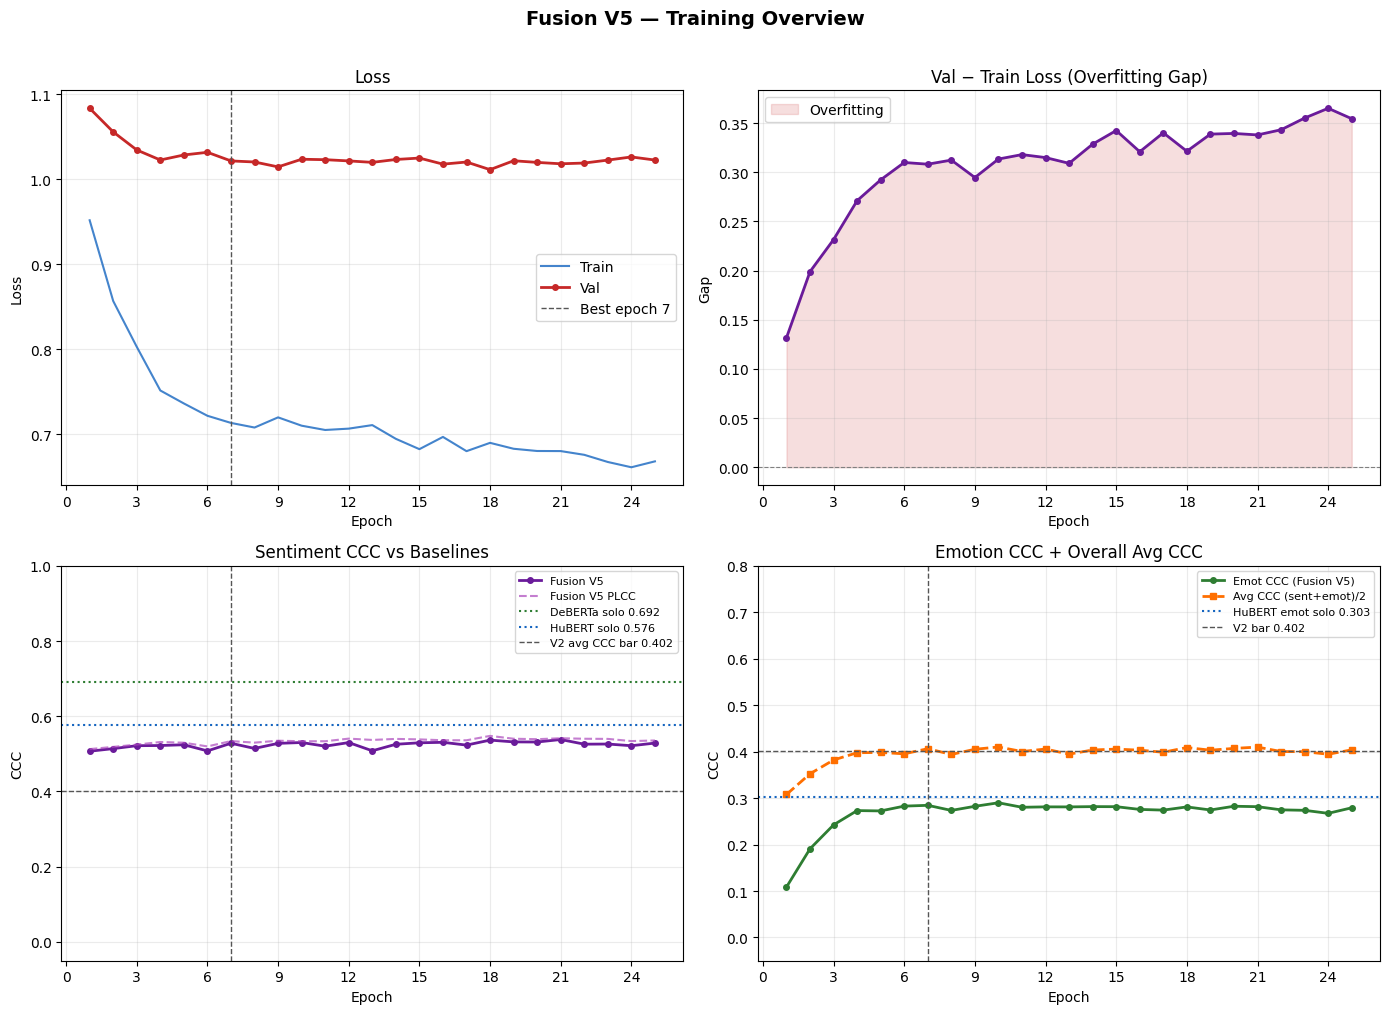

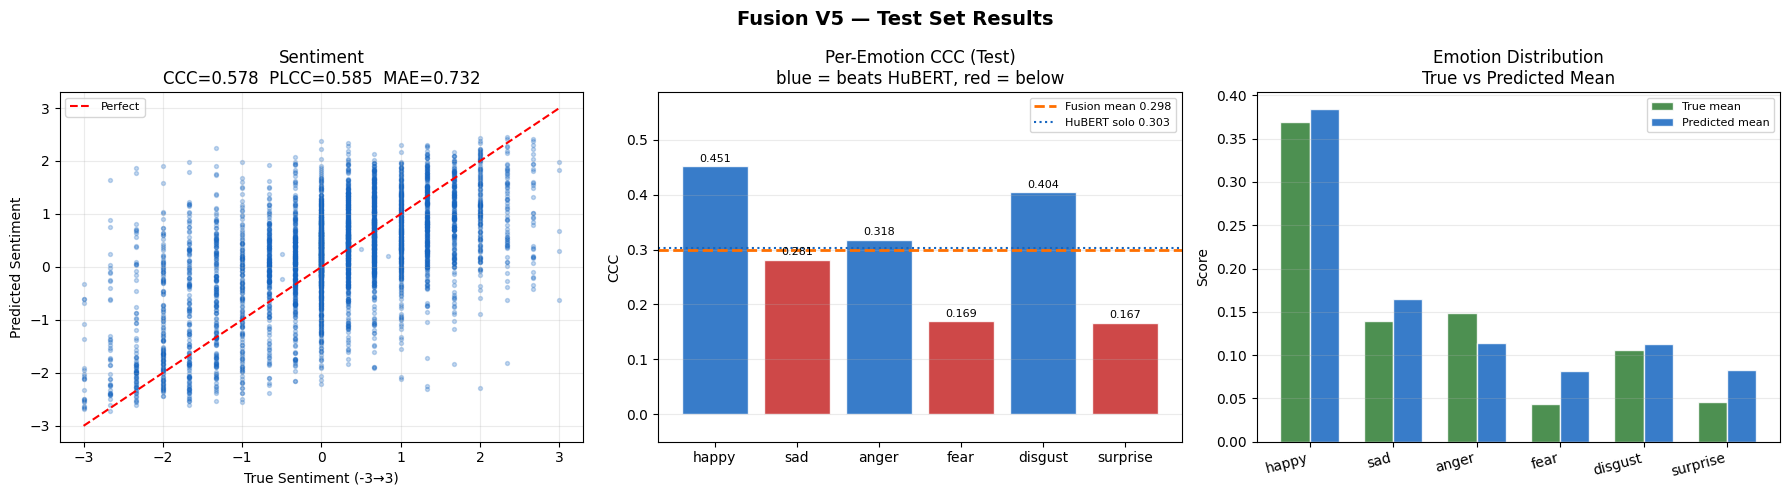

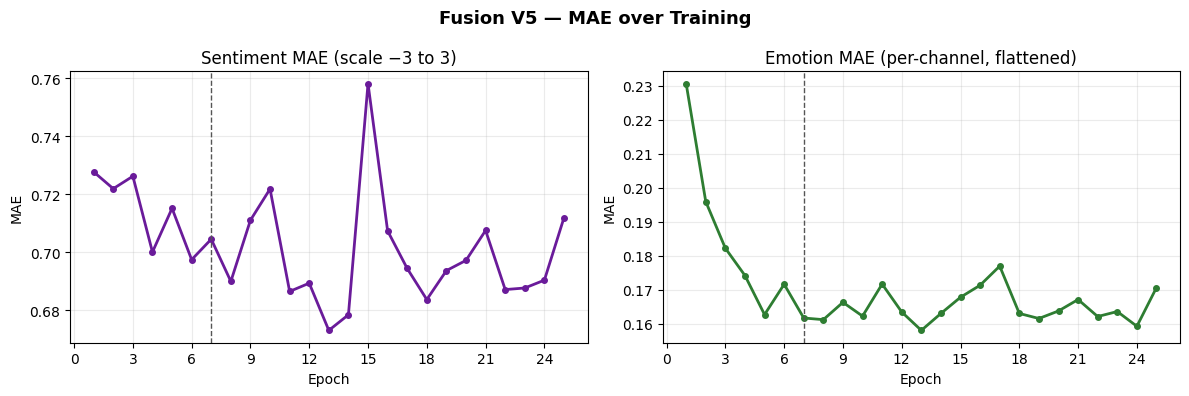


Plots saved to: /content/drive/Shareddrives/AI Capstone/Middle Fusion/fusion-mosei-best


In [ ]:
# Plots
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
from sklearn.metrics import mean_absolute_error

epochs_ran = range(1, len(history["train_loss"]) + 1)

# Figure 1: Training overview (2×2)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Fusion V5 — Training Overview", fontsize=14, fontweight="bold", y=1.01)

# (0,0) Loss curves
ax = axes[0, 0]
ax.plot(epochs_ran, history["train_loss"], label="Train", color="#1565C0", linewidth=1.5, alpha=0.8)
ax.plot(epochs_ran, history["val_loss"],   label="Val",   color="#C62828", linewidth=2,
        marker="o", markersize=4)
if best_epoch:
    ax.axvline(best_epoch, color="#555", linestyle="--", linewidth=1,
               label=f"Best epoch {best_epoch}")
ax.set_title("Loss"); ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
ax.legend(); ax.grid(True, alpha=0.25)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

# (0,1) Val loss − train loss (overfitting gap)
gap = [v - t for v, t in zip(history["val_loss"], history["train_loss"])]
ax = axes[0, 1]
ax.plot(epochs_ran, gap, color="#6A1B9A", linewidth=2, marker="o", markersize=4)
ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.fill_between(epochs_ran, gap, 0,
                where=[g > 0 for g in gap], alpha=0.15, color="#C62828", label="Overfitting")
ax.set_title("Val − Train Loss (Overfitting Gap)")
ax.set_xlabel("Epoch"); ax.set_ylabel("Gap")
ax.legend(); ax.grid(True, alpha=0.25)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

# (1,0) Sentiment CCC + baselines
ax = axes[1, 0]
ax.plot(epochs_ran, history["sent_ccc"], label="Fusion V5", color="#6A1B9A",
        linewidth=2, marker="o", markersize=4)
ax.plot(epochs_ran, history["sent_plcc"], label="Fusion V5 PLCC", color="#AB47BC",
        linewidth=1.5, linestyle="--", alpha=0.7)
ax.axhline(0.6918, color="#2E7D32", linestyle=":",  linewidth=1.5, label="DeBERTa solo 0.692")
ax.axhline(0.5756, color="#1565C0", linestyle=":",  linewidth=1.5, label="HuBERT solo 0.576")
ax.axhline(0.4018, color="#555",    linestyle="--", linewidth=1,   label="V2 avg CCC bar 0.402")
if best_epoch:
    ax.axvline(best_epoch, color="#555", linestyle="--", linewidth=1)
ax.set_title("Sentiment CCC vs Baselines")
ax.set_xlabel("Epoch"); ax.set_ylabel("CCC")
ax.set_ylim(-0.05, 1.0); ax.legend(fontsize=8); ax.grid(True, alpha=0.25)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

# (1,1) Emotion CCC + baselines + avg CCC
ax = axes[1, 1]
avg_ccc_hist = [(s + e) / 2 for s, e in
                zip(history["sent_ccc"], history["mean_emot_ccc"])]
ax.plot(epochs_ran, history["mean_emot_ccc"], label="Emot CCC (Fusion V5)",
        color="#2E7D32", linewidth=2, marker="o", markersize=4)
ax.plot(epochs_ran, avg_ccc_hist, label="Avg CCC (sent+emot)/2",
        color="#FF6F00", linewidth=2, marker="s", markersize=4, linestyle="--")
ax.axhline(0.3027, color="#1565C0", linestyle=":", linewidth=1.5, label="HuBERT emot solo 0.303")
ax.axhline(0.4018, color="#555",    linestyle="--", linewidth=1,  label="V2 bar 0.402")
if best_epoch:
    ax.axvline(best_epoch, color="#555", linestyle="--", linewidth=1)
ax.set_title("Emotion CCC + Overall Avg CCC")
ax.set_xlabel("Epoch"); ax.set_ylabel("CCC")
ax.set_ylim(-0.05, 0.8); ax.legend(fontsize=8); ax.grid(True, alpha=0.25)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/training_overview_v5.png", dpi=150, bbox_inches="tight")
plt.show()

# Figure 2: Test results
fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5))
fig2.suptitle("Fusion V5 — Test Set Results", fontsize=14, fontweight="bold")

# Sentiment scatter
ax = axes2[0]
ax.scatter(sent_true, sent_preds, alpha=0.25, s=8, color="#1565C0", rasterized=True)
lo, hi = min(min(sent_true), min(sent_preds)), max(max(sent_true), max(sent_preds))
ax.plot([lo, hi], [lo, hi], "r--", linewidth=1.5, label="Perfect")
ax.set_xlabel("True Sentiment (-3→3)")
ax.set_ylabel("Predicted Sentiment")
ax.set_title(f"Sentiment\nCCC={sent_ccc_val:.3f}  PLCC={sent_plcc:.3f}  MAE={sent_mae:.3f}")
ax.legend(fontsize=8); ax.grid(True, alpha=0.25)

# Per-emotion CCC bars
ax = axes2[1]
colors = ["#1565C0" if v >= 0.3027 else "#C62828" for v in emot_ccc_scores]
bars = ax.bar(EMOTION_COLS, emot_ccc_scores, color=colors, alpha=0.85, edgecolor="white")
ax.axhline(mean_emot_ccc, color="#FF6F00", linestyle="--", linewidth=2,
           label=f"Fusion mean {mean_emot_ccc:.3f}")
ax.axhline(0.3027, color="#1565C0",  linestyle=":", linewidth=1.5,
           label="HuBERT solo 0.303")
for bar, val in zip(bars, emot_ccc_scores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f"{val:.3f}", ha="center", va="bottom", fontsize=8)
ax.set_title("Per-Emotion CCC (Test)\nblue = beats HuBERT, red = below")
ax.set_ylabel("CCC"); ax.set_ylim(-0.05, max(emot_ccc_scores) * 1.3)
ax.legend(fontsize=8); ax.grid(True, alpha=0.25, axis="y")

# True vs predicted mean per emotion
ax = axes2[2]
x = np.arange(len(EMOTION_COLS)); w = 0.35
ax.bar(x - w/2, emot_true.mean(axis=0),  w, label="True mean",
       color="#2E7D32", alpha=0.85, edgecolor="white")
ax.bar(x + w/2, emot_preds.mean(axis=0), w, label="Predicted mean",
       color="#1565C0", alpha=0.85, edgecolor="white")
ax.set_xticks(x); ax.set_xticklabels(EMOTION_COLS, rotation=15, ha="right")
ax.set_title("Emotion Distribution\nTrue vs Predicted Mean")
ax.set_ylabel("Score"); ax.legend(fontsize=8)
ax.grid(True, alpha=0.25, axis="y")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/test_results_v5.png", dpi=150, bbox_inches="tight")
plt.show()

# Figure 3: MAE curves
fig3, axes3 = plt.subplots(1, 2, figsize=(12, 4))
fig3.suptitle("Fusion V5 — MAE over Training", fontsize=13, fontweight="bold")

ax = axes3[0]
ax.plot(epochs_ran, history["sent_mae"], color="#6A1B9A", linewidth=2, marker="o", markersize=4)
if best_epoch:
    ax.axvline(best_epoch, color="#555", linestyle="--", linewidth=1)
ax.set_title("Sentiment MAE (scale −3 to 3)")
ax.set_xlabel("Epoch"); ax.set_ylabel("MAE"); ax.grid(True, alpha=0.25)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

ax = axes3[1]
ax.plot(epochs_ran, history["emot_mae"], color="#2E7D32", linewidth=2, marker="o", markersize=4)
if best_epoch:
    ax.axvline(best_epoch, color="#555", linestyle="--", linewidth=1)
ax.set_title("Emotion MAE (per-channel, flattened)")
ax.set_xlabel("Epoch"); ax.set_ylabel("MAE"); ax.grid(True, alpha=0.25)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/mae_curves_v5.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nPlots saved to: {OUTPUT_DIR}")